In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, spearmanr
import python_anesthesia_simulator as pas
from scripts.new_hemo_class import NewHemoModel
from scipy.signal import dlsim, TransferFunction

In [26]:
data = pd.read_csv('data/database.csv')
data['TPR'] = (data['MAP'] / (data['HR'] * data['SV'])).clip(0, 0.04)
data['TPR_sim'] = (data['MAP_sim'] / (data['HR_sim'] * data['SV_sim'])).clip(0, 0.04)

In [27]:
caseid = data.caseid.unique()[0]
# caseid = 2029
data_case = data.query('caseid == @caseid')
age = data_case.age.iloc[0]
height = data_case.height.iloc[0]
weight = data_case.weight.iloc[0]
sex = data_case.sex.iloc[0]
bis_base = data_case.bis_base.iloc[0]
hr_base = data_case.hr_base.iloc[0]
map_base = data_case.map_base.iloc[0]
sv_base = data_case.sv_base.iloc[0]


model = "Eleveld"  # Eleveld model
Patient_simu = pas.Patient(
    [age, height, weight, sex],
    model_propo=model,  # "Schnider",
    model_remi=model,  # "Minto",
    model_bis='Fuentes',
    hr_base=hr_base,
    co_base=sv_base*hr_base/1000,  # L to ml
    map_base=map_base
)

Patient_simu_dist = pas.Patient(
    [age, height, weight, sex],
    model_propo=model,  # "Schnider",
    model_remi=model,  # "Minto",
    model_bis='Fuentes',
)

Patient_simu_dist.hemo_pd = NewHemoModel(
        age=Patient_simu_dist.age,
        ts=Patient_simu_dist.ts,
        random=False,
        hr_base=hr_base,
        sv_base=sv_base,  # L to ml
        map_base=map_base
    )
time_max = 30*60

# sv_vec = min
# gain = 1e-6
# min = [-gain, -gain, 0.1, -gain, 0.4, 0.1]
# max = [gain, gain, 10, gain, 5, 10]
# tpr_vec = min
dist_input = np.zeros(time_max)
intubation_time = data_case.intubation_time.iloc[0]
dist_input[intubation_time - int(2*60/1):intubation_time] = 1  # step disturbance after 5 seconds

Patient_simu_dist.hemo_pd.dist_tpr_tau = 1
Patient_simu_dist.hemo_pd.dist_tpr_k = 0.0025/60
Patient_simu_dist.hemo_pd.dist_sv_tau = 60
Patient_simu_dist.hemo_pd.dist_sv_k = 10/60
Patient_simu_dist.hemo_pd.dist_hr_tau = 60
Patient_simu_dist.hemo_pd.dist_hr_k = 10/60



x_hemo = np.zeros((len(data_case['Propofol']), 10))
data_case = data_case.query('Time <= @time_max')
for time in range(len(data_case['Propofol'])):
    Patient_simu.one_step(u_propo=data_case['Propofol'].iloc[time]*20/3600,
    u_remi=data_case['Remifentanil'].iloc[time]*20/3600, noise=False)
    Patient_simu_dist.one_step(u_propo=data_case['Propofol'].iloc[time]*20/3600,
    u_remi=data_case['Remifentanil'].iloc[time]*20/3600, noise=False)
    x_hemo[time,:] = Patient_simu_dist.hemo_pd.x

df_simu = Patient_simu.dataframe
df_simu_dist = Patient_simu_dist.dataframe

# df_simu = Patient_simu.full_sim(
#     u_propo=data_case['Propofol']*20/3600,
#     u_remi=data_case['Remifentanil']*20/3600
#     )
# df_simu_dist = Patient_simu_dist.full_sim(
#     u_propo=data_case['Propofol']*20/3600,
#     u_remi=data_case['Remifentanil']*20/3600
#     )

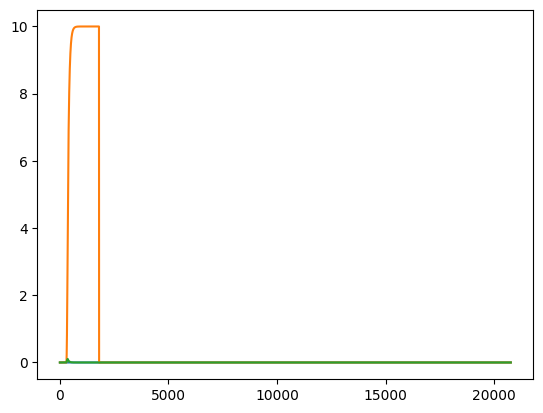

In [28]:
for index in [5,7,9]:
    plt.plot(x_hemo[:,index])
plt.show()

In [29]:
loss = 0
for signal in ['HR', 'MAP', 'SV']:
    error = (df_simu_dist[signal] - data_case[signal]) / data_case[signal]
    error = error.dropna()
    error = error[~(data_case[signal] < 10)]
    loss += np.linalg.norm(error, 2)
print(f'Loss: {loss}')

Loss: 28.804747876229168


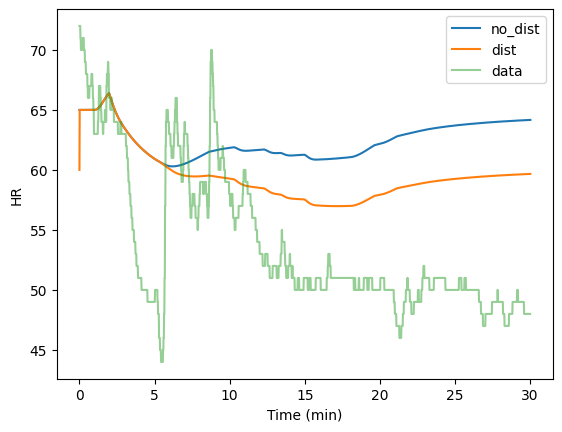

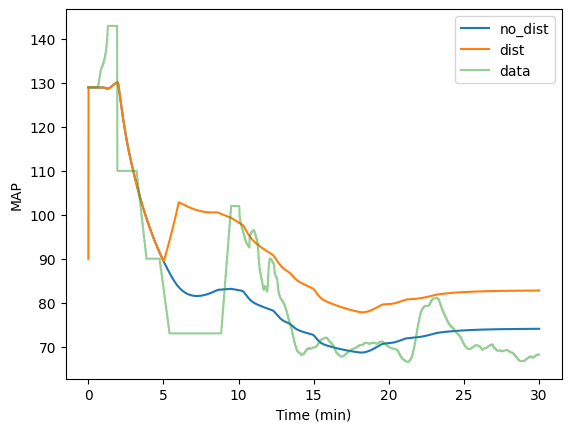

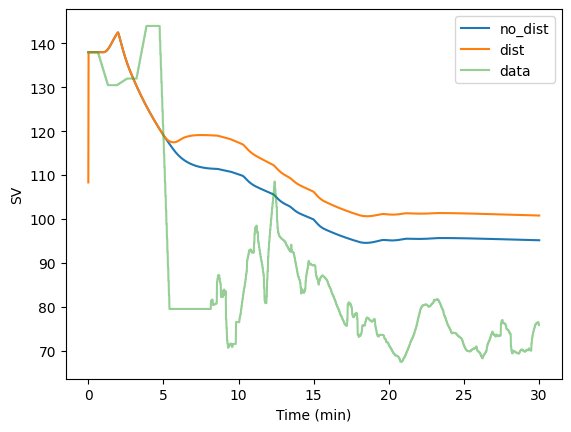

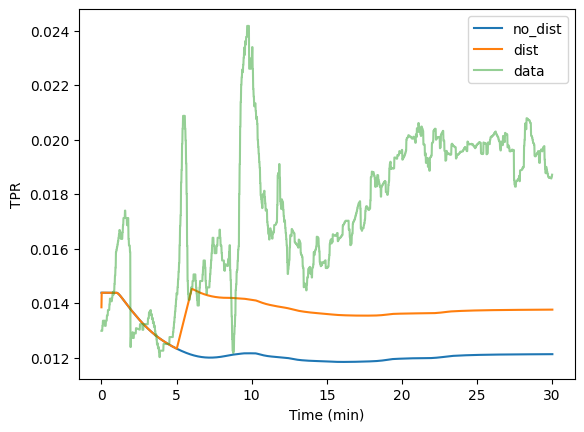

In [30]:
for signal in ['HR', 'MAP', 'SV', 'TPR']:
    plt.figure()
    plt.plot(df_simu['Time']/60, df_simu[signal], label='no_dist')
    plt.plot(df_simu_dist['Time']/60, df_simu_dist[signal], label='dist')
    if signal in data_case.columns:
        plt.plot(data_case['Time']/60, data_case[signal], label='data', alpha=0.5)
    plt.xlabel('Time (min)')
    plt.ylabel(f'{signal}')
    plt.legend()
    plt.show()

In [48]:
signal_list = ['MAP', 'HR', 'SV', 'TPR']
data_sim_dist = pd.read_csv('./data/simulation_disturbance_hand.csv')
data_merged = pd.merge(data, data_sim_dist, on=['caseid', 'Time'], how='left', suffixes=('', '_dist'))
# data_merged['MAP'] = data_merged['NI_MAP']

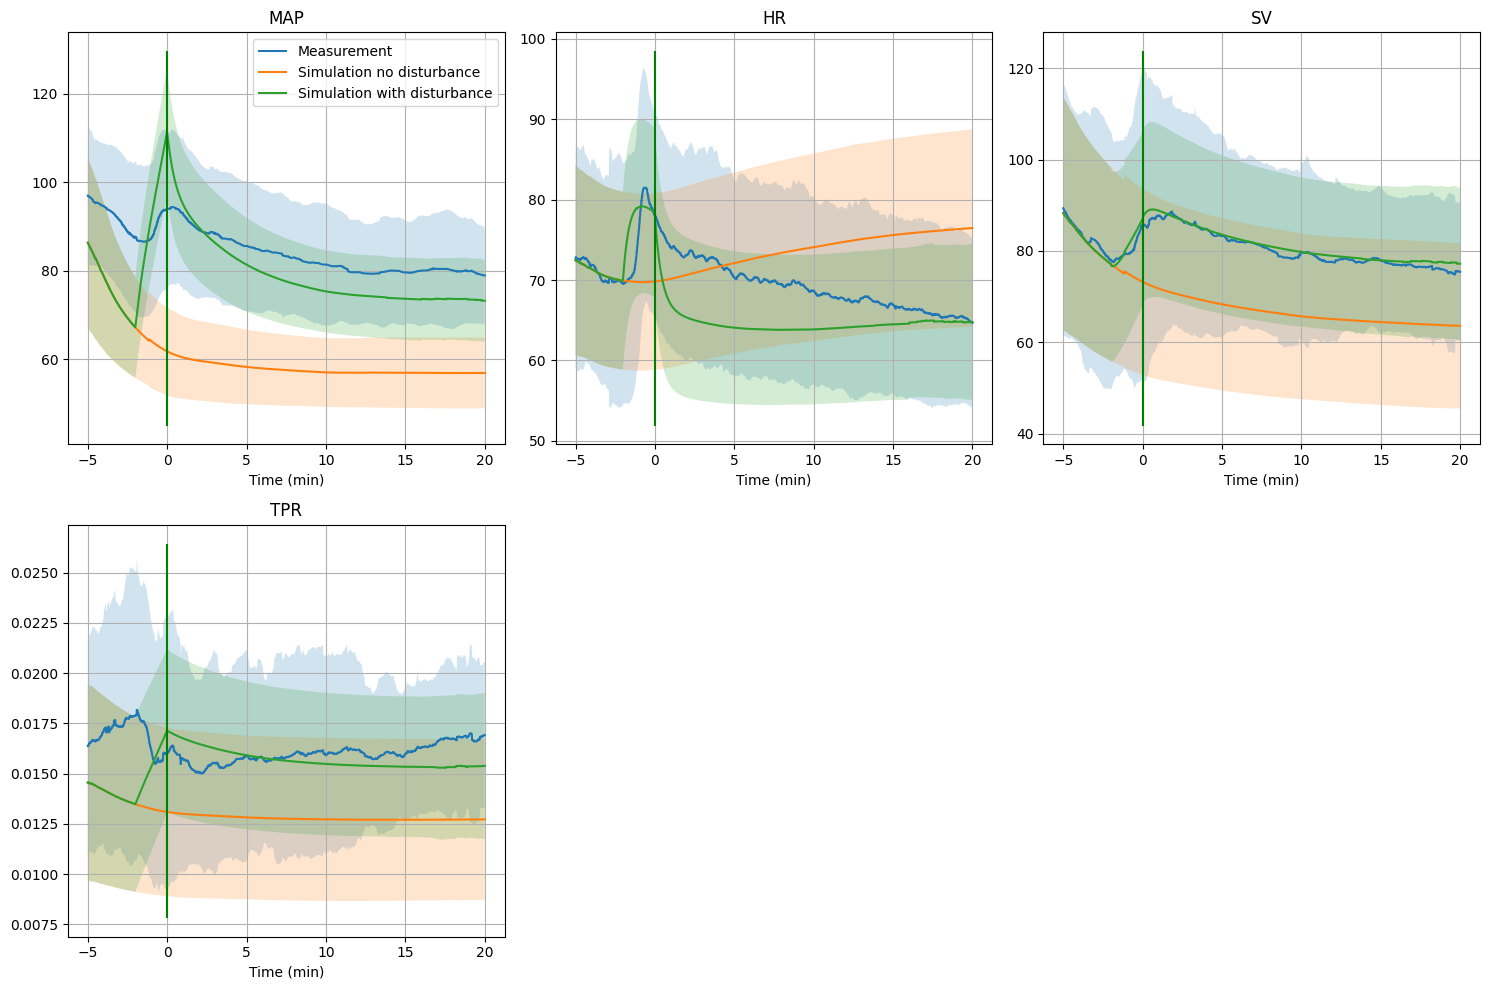

In [49]:

data_merged['Time_aligned'] = data_merged['Time'] - data_merged['intubation_time']
data_intub = data_merged.query("(Time_aligned>= -5*60) & (Time_aligned <=20*60)").copy()
plt.figure(figsize=(15,10))
for i, signal in enumerate(signal_list):
    plt.subplot(2,3,i+1)
    y_measure = data_intub.groupby("Time_aligned")[signal].mean().reset_index()
    y_measure_std = data_intub.groupby("Time_aligned")[signal].std().reset_index()
    y_sim = data_intub.groupby("Time_aligned")[f"{signal}_sim"].mean().reset_index()
    y_sim_std = data_intub.groupby("Time_aligned")[f"{signal}_sim"].std().reset_index()
    y_dist = data_intub.groupby("Time_aligned")[f"{signal}_dist"].mean().reset_index()
    y_dist_std = data_intub.groupby("Time_aligned")[f"{signal}_dist"].std().reset_index()
    x = y_measure['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='Measurement')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, label='Simulation no disturbance')
    plt.fill_between(x, y_sim[f"{signal}_sim"].values-y_sim_std[f"{signal}_sim"].values, y_sim[f"{signal}_sim"].values+y_sim_std[f"{signal}_sim"].values
    , alpha = 0.2)
    plt.plot(x, y_dist[f"{signal}_dist"].values, label='Simulation with disturbance')
    plt.fill_between(x, y_dist[f"{signal}_dist"].values-y_dist_std[f"{signal}_dist"].values, y_dist[f"{signal}_dist"].values+y_dist_std[f"{signal}_dist"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'g')
    plt.grid()
    plt.title(signal)
    if i==0:
        plt.legend()
    plt.xlabel('Time (min)')
# plt.suptitle("Aligned on end of intubation")
plt.tight_layout()
plt.savefig('output/dist_manually_tunned.pdf', dpi=300)   
plt.show()

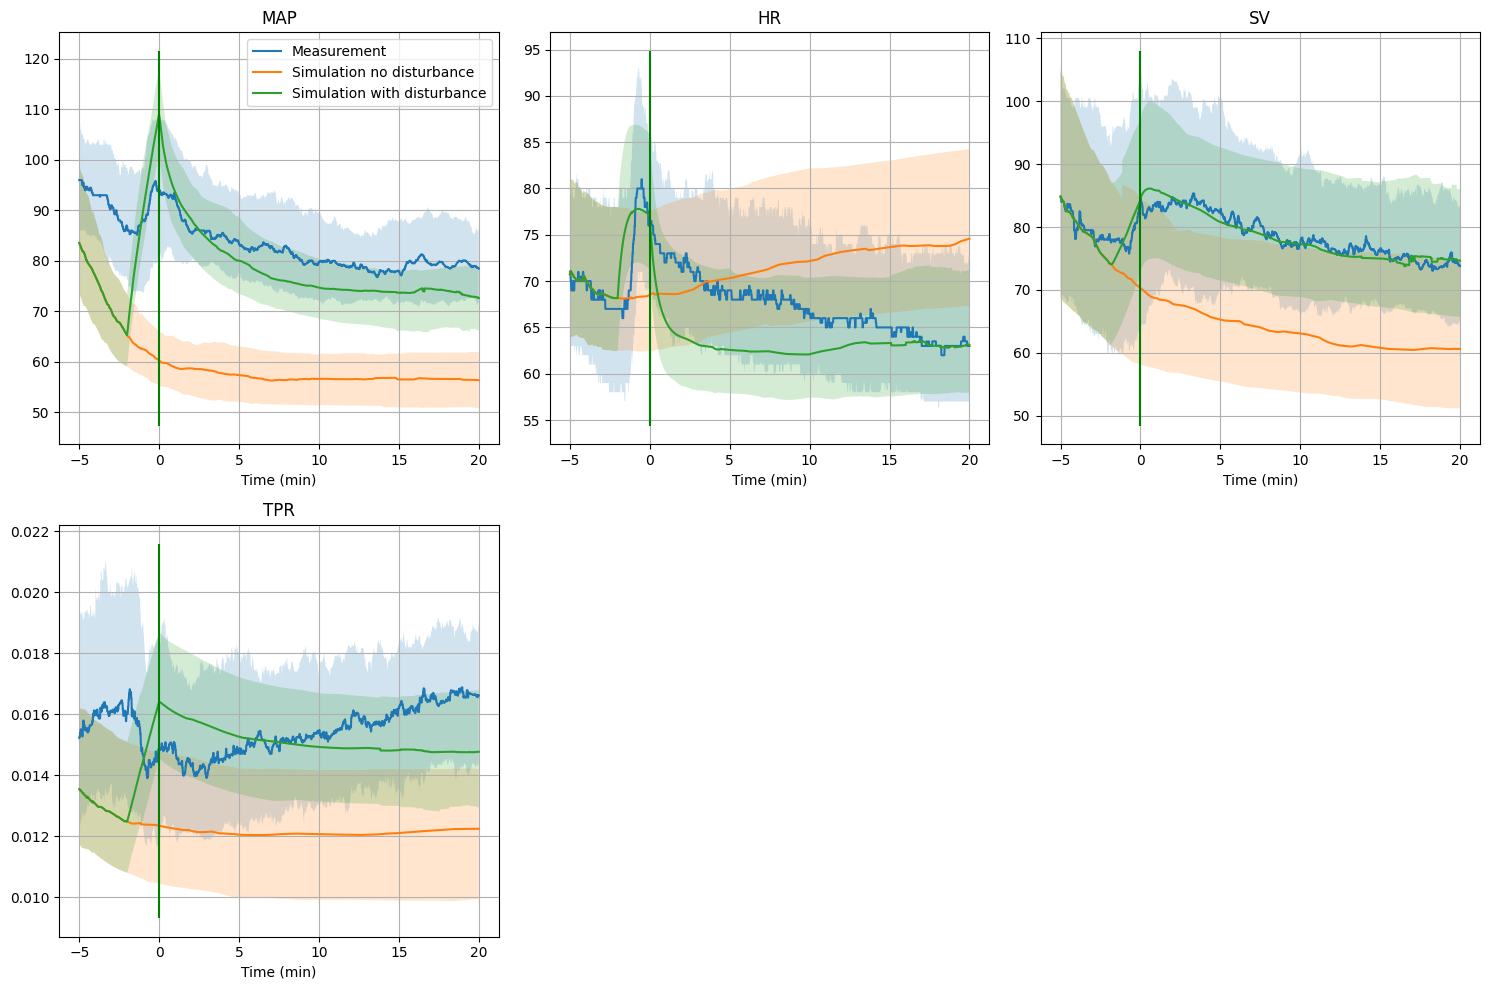

In [33]:

data_merged['Time_aligned'] = data_merged['Time'] - data_merged['intubation_time']
data_intub = data_merged.query("(Time_aligned>= -5*60) & (Time_aligned <=20*60)").copy()
plt.figure(figsize=(15,10))
for i, signal in enumerate(signal_list):
    plt.subplot(2,3,i+1)
    y_measure = data_intub.groupby("Time_aligned")[signal].median().reset_index()
    y_measure_q1 = data_intub.groupby("Time_aligned")[signal].quantile(0.25).reset_index()
    y_measure_q3 = data_intub.groupby("Time_aligned")[signal].quantile(0.75).reset_index()
    y_sim = data_intub.groupby("Time_aligned")[f"{signal}_sim"].median().reset_index()
    y_sim_q1 = data_intub.groupby("Time_aligned")[f"{signal}_sim"].quantile(0.25).reset_index()
    y_sim_q3 = data_intub.groupby("Time_aligned")[f"{signal}_sim"].quantile(0.75).reset_index()
    y_dist = data_intub.groupby("Time_aligned")[f"{signal}_dist"].median().reset_index()
    y_dist_q1 = data_intub.groupby("Time_aligned")[f"{signal}_dist"].quantile(0.25).reset_index()
    y_dist_q3 = data_intub.groupby("Time_aligned")[f"{signal}_dist"].quantile(0.75).reset_index()
    x = y_measure['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='Measurement')
    plt.fill_between(x, y_measure_q1[f"{signal}"].values, y_measure_q3[f"{signal}"].values, alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, label='Simulation no disturbance')
    plt.fill_between(x, y_sim_q1[f"{signal}_sim"].values , y_sim_q3[f"{signal}_sim"].values, alpha = 0.2)
    plt.plot(x, y_dist[f"{signal}_dist"].values, label='Simulation with disturbance')
    plt.fill_between(x, y_dist_q1[f"{signal}_dist"].values, y_dist_q3[f"{signal}_dist"].values, alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'g')
    plt.grid()
    plt.title(signal)
    if i==0:
        plt.legend()
    plt.xlabel('Time (min)')
# plt.suptitle("Aligned on end of intubation")
plt.tight_layout()
plt.savefig('output/dist_v1.pdf', dpi=300)   
plt.show()

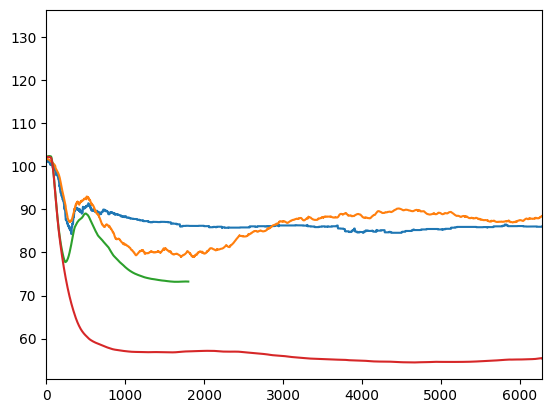

In [56]:
plt.plot(data.groupby('Time')['NI_MAP'].mean())
plt.plot(data.groupby('Time')['MAP'].mean())
plt.plot(data_merged.groupby('Time')['MAP_dist'].mean())
plt.plot(data_merged.groupby('Time')['MAP_sim'].mean())
plt.xlim([0, data.groupby('caseid')['Time'].max().min()])

plt.show()